In [1]:
import gwfit.nr.nr_data_utils as nrutils
import sxs
import numpy as np
import matplotlib.pyplot as plt

sxs.sxs_directory("config")
sxs.write_config(download=True, cache=True, auto_supersede=True)
sxs.read_config()
sxs.sxs_directory("cache")

PosixPath('/home/samanwaya/.cache/sxs')

## Test the utility to filter simulations

In [2]:
simulations = sxs.load("simulations")

df = simulations.dataframe

# Nonspinning BBHs
df_filtered = nrutils.filter_simulations(
    df,
    q=(1, None),
    chi1=(0, 1e-4),
    chi2=(0, 1e-4),
)

df_filtered_sorted = df_filtered.sort_values(
    "reference_mass_ratio"
)  # sorted by increasing mass ratio

nonspinning_circular_labels = df_filtered_sorted.index.to_numpy(dtype=str)
print("Nonspinning circular labels:")
print(nonspinning_circular_labels)

Loading SXS simulations using latest tag 'v3.0.0', published at 2025-05-14T18:17:30Z.
Nonspinning circular labels:
['SXS:BBH:1132' 'SXS:BBH:1154' 'SXS:BBH:1155' 'SXS:BBH:1153'
 'SXS:BBH:3617' 'SXS:BBH:2375' 'SXS:BBH:2376' 'SXS:BBH:2325'
 'SXS:BBH:2326' 'SXS:BBH:2331' 'SXS:BBH:3984' 'SXS:BBH:1166'
 'SXS:BBH:1167' 'SXS:BBH:2265' 'SXS:BBH:2483' 'SXS:BBH:2484'
 'SXS:BBH:3144' 'SXS:BBH:2487' 'SXS:BBH:3619' 'SXS:BBH:2486'
 'SXS:BBH:2489' 'SXS:BBH:2488' 'SXS:BBH:2491' 'SXS:BBH:2490'
 'SXS:BBH:2493' 'SXS:BBH:2707' 'SXS:BBH:2492' 'SXS:BBH:2495'
 'SXS:BBH:1108' 'SXS:BBH:2494' 'SXS:BBH:2480' 'SXS:BBH:2477']


label: SXS:BBH:2488, mass ratio: 6.50
flux ratio = 14.543, area ratio = 1.145


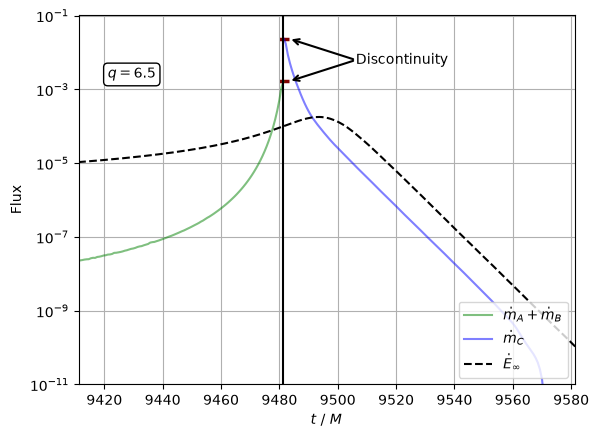

In [5]:
sim_label = 'SXS:BBH:2488'
flux_ratio = []
area_ratio = []
q_vals = []

sim_prem = nrutils.SXSSimulation(
    simulation_label=sim_label,
    initial_cutoff=5300,
    final_cutoff="last_common_time",
)
print(
    f"label: {sim_label}, mass ratio: {sim_prem.metadata.reference_mass_ratio:.2f}"
)

t_ch = sim_prem.metadata.common_horizon_time
q = sim_prem.metadata.reference_mass_ratio

twf, gw_freq = sim_prem.mode_frequency(mode=(2, 2))
_, gw_flux = sim_prem.gw_flux(ell_max=8)
orb_freq = gw_freq / 2.0
# plt.plot(twf,gw_freq)
t, fA, fB = sim_prem.horizon.component_horizon_fluxes(times_to_interpolate=twf)
tc, fC = sim_prem.horizon.common_horizon_flux(times_to_interpolate=twf)
dMdt = fA + fB

taAB, aA, aB = sim_prem.horizon.component_areas(times_to_interpolate=twf)
taC, aC = sim_prem.horizon.common_area(times_to_interpolate=twf)
R_a = aC[0] / (aA[-1] + aB[-1])
R_f = fC[0] / dMdt[-1]
flux_ratio.append(R_f)
area_ratio.append(R_a)
q_vals.append(q)
print(f"flux ratio = {R_f:.3f}, area ratio = {R_a:.3f}")

############## plotting #################
plt.semilogy(t, dMdt, c="green", alpha=0.5, label="$\\dot{m}_A+\\dot{m}_B$")
plt.semilogy(tc, fC, c="b", alpha=0.5, label="$\\dot{m}_C$")
plt.semilogy(twf, gw_flux, c="k", ls="--", label="$\\dot{E}_\\infty$")
plt.scatter(t[-1], dMdt[-1], marker="_", c="maroon", s=50, linewidths=2.5)
plt.scatter(tc[0], fC[0], marker="_", c="maroon", s=50, linewidths=2.5)
plt.axvline(t_ch, c="k")  # ,label='Common horizon \n time')
plt.xlim(t_ch - 70, t_ch + 100)
plt.ylim(
    1e-11,
)
plt.grid()
q_label = (
    f"{int(round(q))}" if np.isclose(q, round(q), atol=1e-3, rtol=0) else f"{q:.1f}"
)
plt.text(
    t_ch - 60,
    2e-3,
    f"$q={q_label}$",
    bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.3"),
)
plt.xlabel("$t~/~M$")
plt.ylabel("Flux")
plt.legend(loc="lower right")

x_text = t_ch + 25
y_text = np.sqrt(dMdt[-1] * fC[0])  # midpoint on log scale

plt.text(
    x_text,
    y_text,
    "Discontinuity",
    va="center",
    # bbox=dict(facecolor="white", edgecolor="black", pad=0.3)
)

# Upper arrow
plt.annotate(
    "",
    xy=(t_ch + 2, dMdt[-1]),
    xytext=(x_text, y_text),
    arrowprops=dict(arrowstyle="->", lw=1.5),
)

# Lower arrow
plt.annotate(
    "",
    xy=(t_ch + 2, fC[0]),
    xytext=(x_text, y_text),
    arrowprops=dict(arrowstyle="->", lw=1.5),
)
plt.show()